# # 01 EDA: Fake job postings

In [53]:
# Imports and settings
import html
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [54]:
RANDOM_STATE = 42  # reused everywhere for reproducibility
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/fake_job_postings.csv")
CLEAN_PATH = Path("../data/jobs_clean.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    """Save the figure object to reports/figures/, then display it."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

In [55]:
# Load
df = pd.read_csv(DATA_PATH)
RAW_FEATURES = df.columns.drop(["job_id", "fraudulent"])  # original columns only
print(df.shape)

(17880, 18)


In [56]:
# Inspect
df.info()
print(df["fraudulent"].value_counts())
print(df.isna().sum())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


# Duplicates
# Checked before any analysis so every number below uses the same rows.

In [57]:
dups = df.duplicated(subset=RAW_FEATURES)
print("Duplicates by content:", dups.sum())
print(df[dups]["fraudulent"].value_counts())

labels_per_group = (
    df[df.duplicated(subset=RAW_FEATURES, keep=False)]
    .groupby(list(RAW_FEATURES), dropna=False)["fraudulent"]
    .nunique()
)
n_conflicts = (labels_per_group > 1).sum()
print("Groups with conflicting labels:", n_conflicts)
assert n_conflicts == 0, "Conflicting labels found: decide how to handle them first"

Duplicates by content: 281
fraudulent
0    271
1     10
Name: count, dtype: int64
Groups with conflicting labels: 0


In [58]:
before = len(df)
df = df.drop_duplicates(subset=RAW_FEATURES, keep="first").reset_index(drop=True)
print(f"Rows: {before} -> {len(df)}")

counts = df["fraudulent"].value_counts()
print(counts)
print("Fake rate:", round(counts[1] / len(df) * 100, 2), "%")

Rows: 17880 -> 17599
fraudulent
0    16743
1      856
Name: count, dtype: int64
Fake rate: 4.86 %


# Dropped exact duplicate postings (no label conflicts) so the same posting
# cannot land in both train and test. Only 10 fake postings were lost.

In [59]:
# Missing-value flags (created BEFORE filling, otherwise the information is lost)
df["has_company_profile"] = df["company_profile"].notna().astype(int)
df["has_salary"] = df["salary_range"].notna().astype(int)

In [60]:
# Fraud rate when a field is present vs missing
for col in ["salary_range", "company_profile", "department", "benefits", "required_education"]:
    rate = df.groupby(df[col].isna())["fraudulent"].mean() * 100
    print(col)
    print(rate.round(2).rename({False: "present", True: "missing"}))
    print()

salary_range
salary_range
present    7.82
missing    4.30
Name: fraudulent, dtype: float64

company_profile
company_profile
present     1.93
missing    17.67
Name: fraudulent, dtype: float64

department
department
present    5.29
missing    4.63
Name: fraudulent, dtype: float64

benefits
benefits
present    4.74
missing    5.05
Name: fraudulent, dtype: float64

required_education
required_education
present    4.30
missing    5.54
Name: fraudulent, dtype: float64



# A missing company profile is the strongest signal: those postings are fake
# about 9 times more often than postings with a profile (fill in the rates from
# the output above). Postings that list a salary are fake MORE often, the
# opposite of what we expected. benefits, department and required_education
# show little difference.

In [61]:
# Fake rate by the existing binary columns
for col in ["has_company_logo", "telecommuting", "has_questions"]:
    print(col)
    print((df.groupby(col)["fraudulent"].mean() * 100).round(2), "\n")

print(df["telecommuting"].value_counts())  # how reliable is the remote rate?

# Do logo and profile overlap?
print(pd.crosstab(df["has_company_logo"], df["has_company_profile"], normalize="index").round(2))

has_company_logo
has_company_logo
0    15.84
1     2.02
Name: fraudulent, dtype: float64 

telecommuting
telecommuting
0    4.70
1    8.49
Name: fraudulent, dtype: float64 

has_questions
has_questions
0    6.79
1    2.88
Name: fraudulent, dtype: float64 

telecommuting
0    16845
1      754
Name: count, dtype: int64
has_company_profile     0     1
has_company_logo               
0                    0.72  0.28
1                    0.05  0.95


# No logo, no screening questions and remote postings all have higher fake
# rates (fill in from output). The logo and profile flags overlap but are not
# identical, so both are kept.

In [62]:
# Fill missing values with constants (safe before the split: nothing is learned from data)
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
cat_cols = ["location", "department", "salary_range", "employment_type",
            "required_experience", "required_education", "industry", "function"]
df[text_cols] = df[text_cols].fillna("")
df[cat_cols] = df[cat_cols].fillna("Unknown")

# Length features
df["desc_length"] = df["description"].str.len()
df["desc_words"] = df["description"].str.split().str.len()

# Country: location looks like "US, NY, New York", so take the part before the first comma
df["country"] = df["location"].str.split(",").str[0].str.strip()
df.loc[df["country"] == "", "country"] = "Unknown"

# One text column for TF-IDF later
df["text"] = df[text_cols].agg(" ".join, axis=1)

df[["has_company_profile", "has_salary", "desc_length", "desc_words", "country"]].describe(include="all")

,has_company_profile,has_salary,desc_length,desc_words,country
count,17599.000000,17599.000000,17599.000000,17599.000000,17599
unique,NaN,NaN,NaN,NaN,91
top,NaN,NaN,NaN,NaN,US
freq,NaN,NaN,NaN,NaN,10460
mean,0.813512,0.160634,1217.205125,170.316779,NaN
std,0.389511,0.367204,895.310918,123.351593,NaN
min,0.000000,0.000000,0.000000,0.000000,NaN
25%,1.000000,0.000000,604.000000,87.000000,NaN
50%,1.000000,0.000000,1017.000000,145.000000,NaN
75%,1.000000,0.000000,1585.500000,224.000000,NaN


# Short descriptions are fake more often than medium-long ones, but the
# longest group rises again, so the relationship is not linear. The US has the
# highest fake rate while several countries have none, which probably reflects
# how the data was collected (bias to discuss in the report).

In [63]:
# Masked tokens in the text: do they predict fraud?
for tok in ["#URL_", "#EMAIL_", "#PHONE_"]:
    has = df["text"].str.contains(tok)
    print(tok, "| rows:", has.sum(),
          "| fake rate with:", round(df.loc[has, "fraudulent"].mean() * 100, 2),
          "| without:", round(df.loc[~has, "fraudulent"].mean() * 100, 2))

#URL_ | rows: 5550 | fake rate with: 4.77 | without: 4.9
#EMAIL_ | rows: 1315 | fake rate with: 13.08 | without: 4.2
#PHONE_ | rows: 516 | fake rate with: 15.31 | without: 4.55


In [64]:
# Clean the text. Each token is #URL_/#EMAIL_/#PHONE_ + a hex string, with no
# closing '#'. Tokens can be stuck together, so do NOT consume a trailing '#'.
TOKEN_MAP = {"URL": " urltoken ", "EMAIL": " emailtoken ", "PHONE": " phonetoken "}

def clean_text(s):
    s = html.unescape(s)                 # &amp; becomes &
    s = s.replace("\xa0", " ")           # non-breaking space becomes a normal space
    s = re.sub(r"#(URL|EMAIL|PHONE)_[0-9a-fA-F]+", lambda m: TOKEN_MAP[m.group(1)], s)
    return re.sub(r"\s+", " ", s).strip().lower()

# Flags come from the RAW text, before cleaning
df["has_email"] = df["text"].str.contains("#EMAIL_").astype(int)
df["has_phone"] = df["text"].str.contains("#PHONE_").astype(int)
df["text_clean"] = df["text"].map(clean_text)

# Verify against independent counts (these fail loudly if the cleaning is wrong)
for name, raw_tok, clean_tok in [("email", "#EMAIL_", "emailtoken"),
                                 ("phone", "#PHONE_", "phonetoken"),
                                 ("url", "#URL_", "urltoken")]:
    n_raw = df["text"].str.contains(raw_tok).sum()
    n_clean = df["text_clean"].str.contains(clean_tok).sum()
    print(f"{name}: raw {n_raw} | cleaned {n_clean}")
    assert n_raw == n_clean, f"{name} tokens lost during cleaning"

print(df.loc[df["has_email"].idxmax(), "text_clean"][:200])

email: raw 1315 | cleaned 1315
phone: raw 516 | cleaned 516
url: raw 5550 | cleaned 5550
asp.net developer job opportunity at united states,new jersey position : urltoken # developerjob location :united states-new jersey-jersey cityus work status required : ead / green card / us citizens 


# Emails and phone numbers in the text raise the fake rate to about 3 times the
# baseline; URLs show no signal, so no URL flag. Tokens are replaced by one
# generic word each because every hex string is unique and would be noise for TF-IDF.

In [65]:
# Plot helpers (after the final df exists)
overall = df["fraudulent"].mean() * 100   # reference line

def fake_rate(by):
    """Fake rate (%) for each group of a column."""
    return df.groupby(by, observed=True)["fraudulent"].mean() * 100

def flag_plot(cols, name):
    """One bar chart per 0/1 column, with the overall fake rate as a dashed line."""
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 4), sharey=True)
    for ax, col in zip(axes, cols):
        rates = fake_rate(col)
        ax.bar(["No", "Yes"], rates.values, color=["#4C78A8", "#E45756"])
        ax.axhline(overall, ls="--", color="grey")
        for i, v in enumerate(rates.values):
            ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
        ax.set_title(col)
    axes[0].set_ylabel("Fake rate (%)")
    plt.tight_layout()
    save_fig(fig, name)

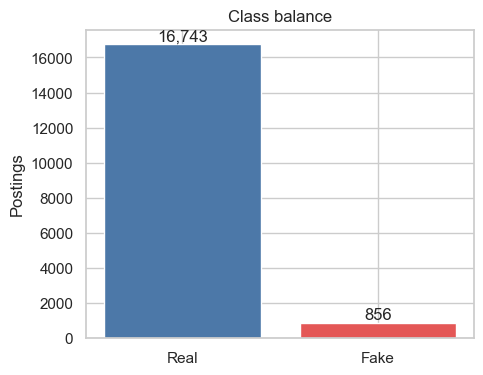

In [66]:
# Plot 1: class balance
counts = df["fraudulent"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Real", "Fake"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_ylabel("Postings")
ax.set_title("Class balance")
save_fig(fig, "01_class_balance")

# Only 4.86% of postings are fake (856 of 17,599), so accuracy is misleading.
# We use fake-class F1, recall and PR-AUC.

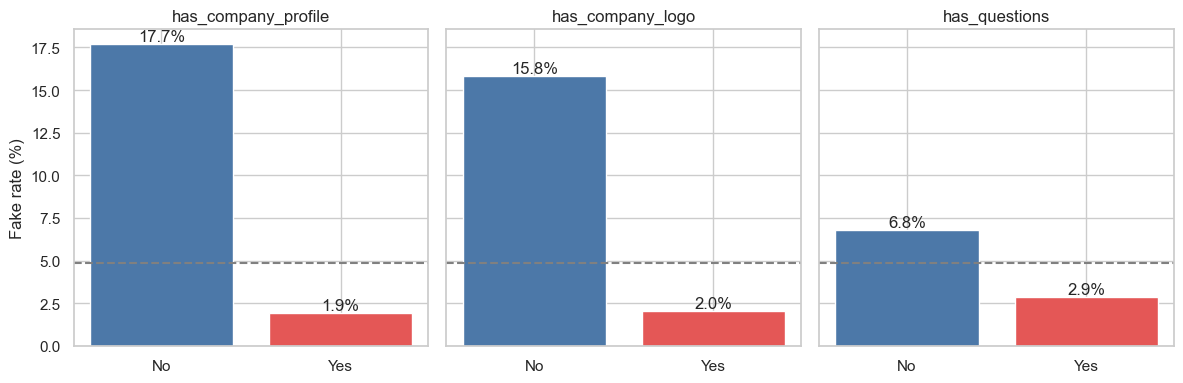

In [67]:
# Plot 2: profile, logo, screening questions
flag_plot(["has_company_profile", "has_company_logo", "has_questions"], "02_profile_logo_questions")

# Postings with no company profile, no logo or no screening questions are fake
# far more often than the overall rate (dashed line). Fill in the largest gap from the plot.

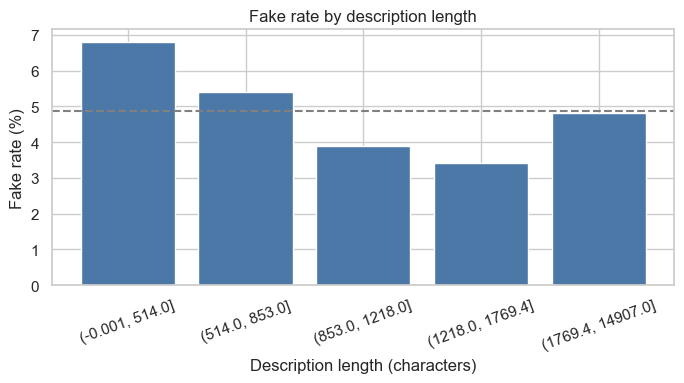

In [68]:
# Plot 3: description length
df["len_bin"] = pd.qcut(df["desc_length"], 5, duplicates="drop")
rates = fake_rate("len_bin")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(rates)), rates.values, color="#4C78A8")
ax.axhline(overall, ls="--", color="grey")
ax.set_xticks(range(len(rates)))
ax.set_xticklabels([str(i) for i in rates.index], rotation=20)
ax.set_xlabel("Description length (characters)")
ax.set_ylabel("Fake rate (%)")
ax.set_title("Fake rate by description length")
plt.tight_layout()
save_fig(fig, "03_description_length")

# Short descriptions are fake about twice as often as medium-long ones, but the
# longest group rises again, so a single linear length feature will not capture it.

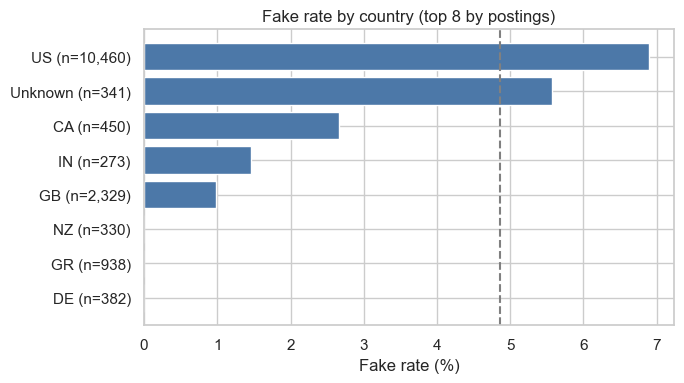

In [69]:
# Plot 4: country (top 8 by number of postings)
top = df["country"].value_counts().head(8).index
n = df["country"].value_counts()[top]
rates = (df[df["country"].isin(top)].groupby("country")["fraudulent"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([f"{c} (n={n[c]:,})" for c in rates.index], rates.values, color="#4C78A8")
ax.axvline(overall, ls="--", color="grey")
ax.set_xlabel("Fake rate (%)")
ax.set_title("Fake rate by country (top 8 by postings)")
plt.tight_layout()
save_fig(fig, "04_country")

# The US has by far the highest fake rate while DE, GR and NZ have none. This may
# reflect how the data was collected, so country is treated with caution (bias).

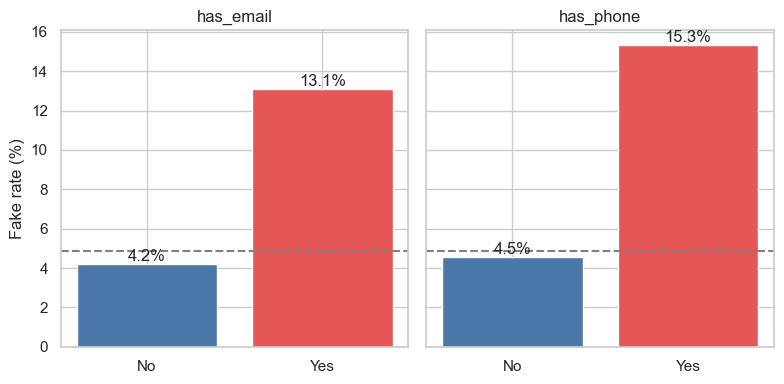

In [70]:
# Plot 5: email and phone in the text
flag_plot(["has_email", "has_phone"], "05_email_phone")

# Postings with an email or phone number in the text are fake about 3 times as
# often as those without. URLs showed no such gap.

In [71]:
print("Empty descriptions:", (df["desc_length"] == 0).sum())

df.drop(columns=["len_bin"]).to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH, "| rows:", len(df))

print([(p.name, p.stat().st_size // 1024, "KB") for p in sorted(FIG_DIR.glob("*.png"))])

Empty descriptions: 1
Saved: ..\data\jobs_clean.csv | rows: 17599
[('01_class_balance.png', 27, 'KB'), ('02_profile_logo_questions.png', 38, 'KB'), ('03_description_length.png', 45, 'KB'), ('04_country.png', 40, 'KB'), ('05_email_phone.png', 26, 'KB')]
